<a href="https://colab.research.google.com/github/miruthulag004/FUNDAMENTALS-OF-DATA-SCIENCE/blob/main/25070421_MIRUTHULA_G_EX_NO_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First five rows of the dataset:
         Date    Product  Sales  Quantity Region
0  2023-01-01  Product A    200         4  North
1  2023-01-02  Product B    150         3  South
2  2023-01-03  Product A    220         5  North
3  2023-01-04  Product C    300         6   East
4  2023-01-05  Product B    180         4   West

Missing values in each column:
Date        0
Product     0
Sales       0
Quantity    0
Region      0
dtype: int64

Summary statistics:
                      Date       Sales   Quantity
count                   16   16.000000  16.000000
mean   2023-01-08 12:00:00  243.750000   5.375000
min    2023-01-01 00:00:00  150.000000   3.000000
25%    2023-01-04 18:00:00  195.000000   4.000000
50%    2023-01-08 12:00:00  235.000000   5.500000
75%    2023-01-12 06:00:00  302.500000   7.000000
max    2023-01-16 00:00:00  340.000000   8.000000
std                    NaN   67.317655   1.746425

Total sales and quantity by product:
     Product  Sales  Quantity
0  Product A   1250 

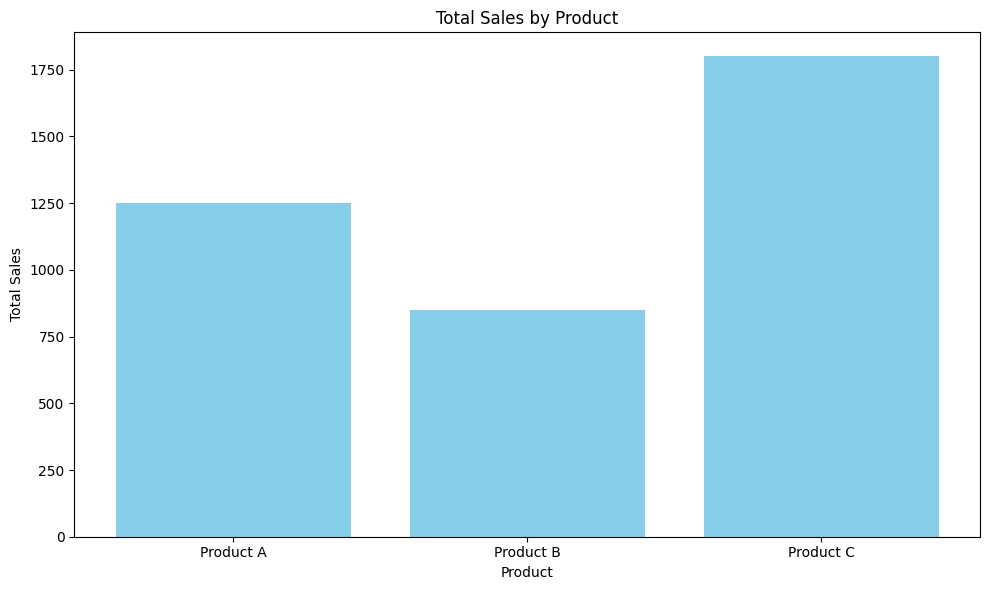

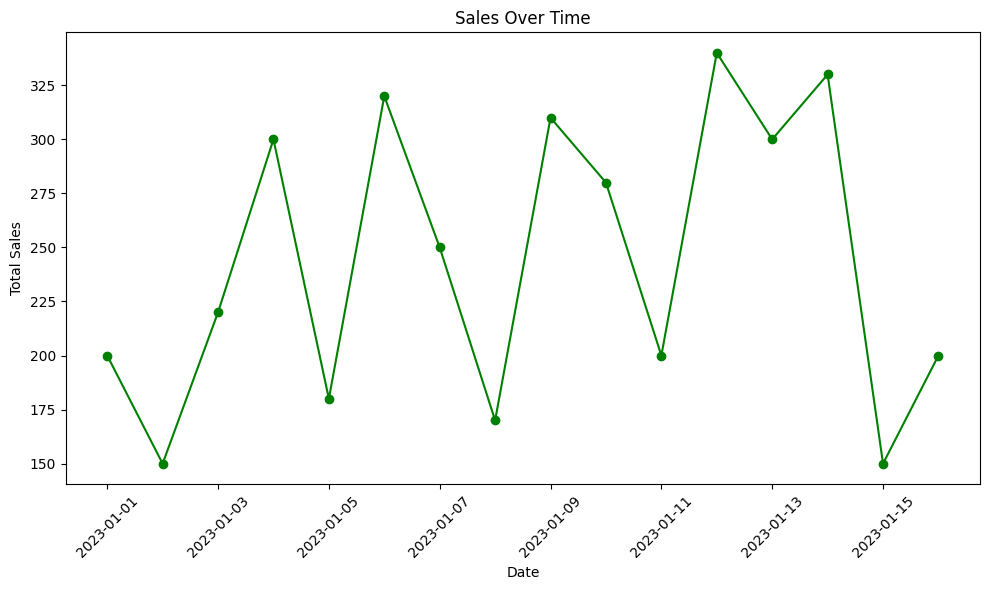


Sales by region and product:
Product  Product A  Product B  Product C
Region                                  
East             0          0       1800
North         1250          0          0
South            0        320          0
West             0        530          0

Correlation matrix:
             Sales  Quantity
Sales     1.000000  0.956916
Quantity  0.956916  1.000000


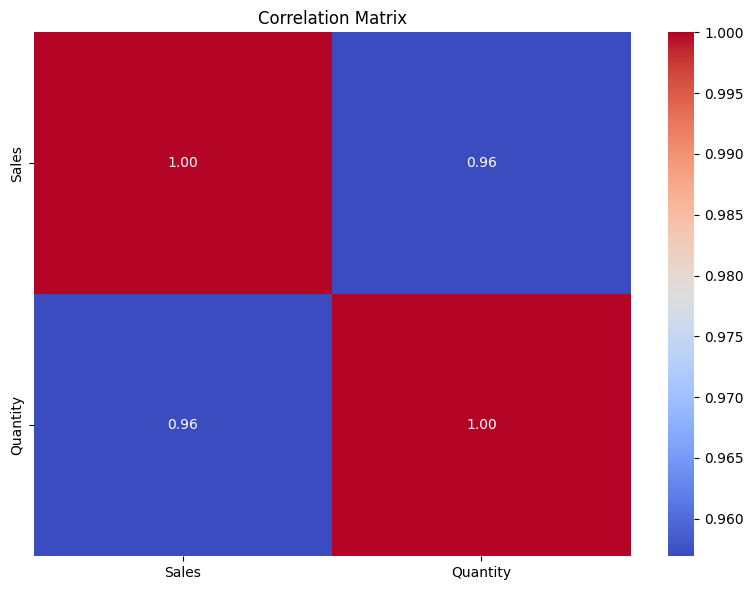


Data preprocessing and visualization completed successfully!


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Create sample sales data
data = {
    'Date': [
        '2023-01-01', '2023-01-02', '2023-01-03', '2023-01-04',
        '2023-01-05', '2023-01-06', '2023-01-07', '2023-01-08',
        '2023-01-09', '2023-01-10', '2023-01-11', '2023-01-12',
        '2023-01-13', '2023-01-14', '2023-01-15', '2023-01-16'
    ],
    'Product': [
        'Product A', 'Product B', 'Product A', 'Product C',
        'Product B', 'Product C', 'Product A', 'Product B',
        'Product C', 'Product A', 'Product B', 'Product C',
        'Product A', 'Product C', 'Product B', 'Product C'
    ],
    'Sales': [
        200, 150, 220, 300, 180, 320, 250, 170,
        310, 280, 200, 340, 300, 330, 150, 200
    ],
    'Quantity': [
        4, 3, 5, 6, 4, 7, 6, 4,
        7, 6, 5, 8, 7, 8, 3, 3
    ],
    'Region': [
        'North', 'South', 'North', 'East',
        'West', 'East', 'North', 'South',
        'East', 'North', 'West', 'East',
        'North', 'East', 'West', 'East'
    ]
}

df_sample = pd.DataFrame(data)
df_sample.to_csv('sales-data.csv', index=False)

# Step 2: Load the CSV file
file_path = 'sales-data.csv'
df = pd.read_csv(file_path)

print("First five rows of the dataset:")
print(df.head())

# Step 3: Check for missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# Step 4: Data preprocessing
df['Sales'] = df['Sales'].fillna(df['Sales'].mean())
df.dropna(subset=['Product', 'Quantity', 'Region', 'Date'], inplace=True)

# Convert Date column to datetime format
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df.dropna(subset=['Date'], inplace=True)

# Step 5: Display summary statistics
print("\nSummary statistics:")
print(df.describe())

# Step 6: Group by product and calculate total sales and quantity
product_summary = df.groupby('Product').agg({
    'Sales': 'sum',
    'Quantity': 'sum'
}).reset_index()

print("\nTotal sales and quantity by product:")
print(product_summary)

# Step 7: Bar chart of total sales by product
plt.figure(figsize=(10, 6))
plt.bar(product_summary['Product'], product_summary['Sales'], color='skyblue')
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.title('Total Sales by Product')
plt.tight_layout()
plt.show()

# Step 8: Line chart of sales over time
sales_over_time = df.groupby('Date', as_index=False)['Sales'].sum()

plt.figure(figsize=(10, 6))
plt.plot(sales_over_time['Date'], sales_over_time['Sales'],
         marker='o', color='green')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.title('Sales Over Time')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Step 9: Pivot table for sales by region and product
pivot_table = df.pivot_table(
    values='Sales',
    index='Region',
    columns='Product',
    aggfunc='sum',
    fill_value=0
)

print("\nSales by region and product:")
print(pivot_table)

# Step 10: Correlation matrix for numeric columns only
correlation_matrix = df[['Sales', 'Quantity']].corr()

print("\nCorrelation matrix:")
print(correlation_matrix)

# Step 11: Heatmap of the correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

print("\nData preprocessing and visualization completed successfully!")
